In [2]:
from pathlib import Path
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode

SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = 8

# ImageNet 정규화 기준
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

# Padding 색상 (RGB 0~255)
PADDING_COLOR = tuple(round(m * 255) for m in MEAN)

print(PADDING_COLOR)

(124, 116, 104)


In [3]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)

In [5]:
DATA_DIR = Path("../data")
META_PATH = DATA_DIR / "metadata.csv"

df = pd.read_csv(META_PATH)

print(df.shape)
display(df.head())

(2031, 12)


,image_id,image_path,split,target_id,class_name,class_name_ko,source_filename,original_split,group_id,width,height,file_size_bytes
0,s40_0004dbd129ba7b27e4e2,images/test/s40_0004dbd129ba7b27e4e2.jpg,test,5,running,달리기,running_081.jpg,test,group_s40_0004dbd129ba7b27e4e2,400,562,72862
1,s40_0010d8bdd8852b56c7bd,images/test/s40_0010d8bdd8852b56c7bd.jpg,test,6,shooting_an_arrow,활쏘기,shooting_an_arrow_160.jpg,test,group_s40_0010d8bdd8852b56c7bd,236,200,24245
2,s40_00371fc2f260232bcce5,images/train/s40_00371fc2f260232bcce5.jpg,train,2,riding_a_bike,자전거 타기,riding_a_bike_113.jpg,train,group_s40_00371fc2f260232bcce5,440,300,48375
3,s40_00463f8daae9482a6352,images/test/s40_00463f8daae9482a6352.jpg,test,6,shooting_an_arrow,활쏘기,shooting_an_arrow_018.jpg,test,group_s40_00463f8daae9482a6352,592,400,62964
4,s40_005f932a385e8666e04e,images/test/s40_005f932a385e8666e04e.jpg,test,7,throwing_frisby,프리스비 던지기,throwing_frisby_199.jpg,test,group_s40_005f932a385e8666e04e,846,600,161415


In [6]:
train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "val"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 640
Validation: 160
Test: 1231


### Resize + Padding 함수 구현

In [7]:
def resize_with_padding(image, size=IMAGE_SIZE, fill=PADDING_COLOR):
    # 원본 이미지 크기
    width, height = image.size

    # 종횡비를 유지하기 위한 배율 계산
    scale = size / max(width, height)

    new_width = max(1, round(width * scale))
    new_height = max(1, round(height * scale))

    # Resize
    image = TF.resize(
        image,
        [new_height, new_width],
        interpolation=InterpolationMode.BILINEAR
    )

    # Padding 크기 계산
    pad_left = (size - new_width) // 2
    pad_top = (size - new_height) // 2

    pad_right = size - new_width - pad_left
    pad_bottom = size - new_height - pad_top

    # Padding 적용
    image = TF.pad(
        image,
        [pad_left, pad_top, pad_right, pad_bottom],
        fill=fill,
        padding_mode="constant"
    )

    return image

In [8]:
# Train 이미지 1장 선택
sample = train_df.iloc[0]

image_path = DATA_DIR / sample["image_path"]

# RGB 이미지로 불러오기
with Image.open(image_path) as img:
    original_image = img.convert("RGB")

# Resize + Padding 적용
processed_image = resize_with_padding(original_image)

print("Class:", sample["class_name_ko"])
print("Original Size:", original_image.size)
print("Processed Size:", processed_image.size)

Class: 자전거 타기
Original Size: (440, 300)
Processed Size: (224, 224)


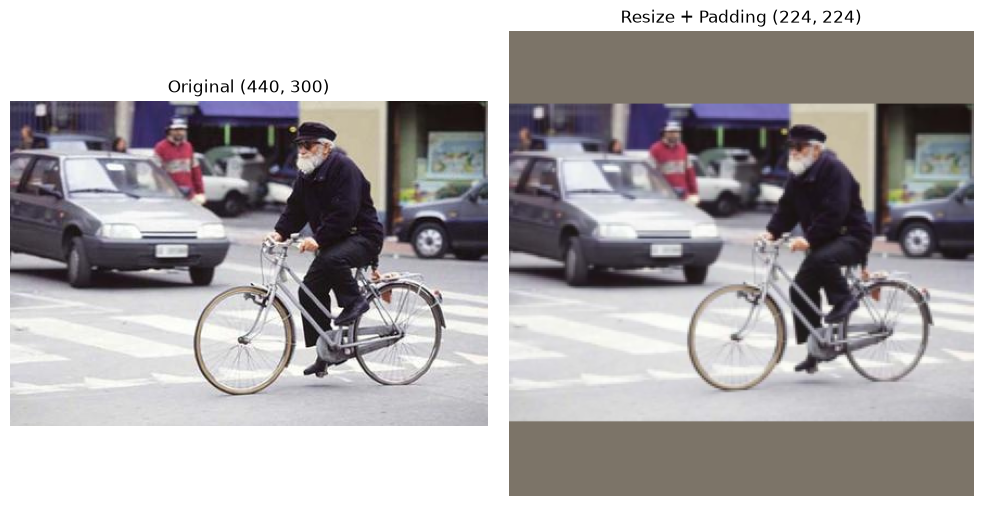

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# 원본 이미지
axes[0].imshow(original_image)
axes[0].set_title(f"Original {original_image.size}")
axes[0].axis("off")

# 전처리 이미지
axes[1].imshow(processed_image)
axes[1].set_title(f"Resize + Padding {processed_image.size}")
axes[1].axis("off")

plt.tight_layout()
plt.show()

#### ToTensor 및 Normalize

In [10]:
# 공통 Transform 정의
common_transform = transforms.Compose([
    transforms.Lambda(resize_with_padding),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

train_transform = common_transform
val_transform = common_transform
test_transform = common_transform

image_tensor = common_transform(original_image)

print("Type:", type(image_tensor))
print("Shape:", image_tensor.shape)
print("Dtype:", image_tensor.dtype)
print("Min:", image_tensor.min().item())
print("Max:", image_tensor.max().item())

Type: <class 'torch.Tensor'>
Shape: torch.Size([3, 224, 224])
Dtype: torch.float32
Min: -1.7906161546707153
Max: 2.640000104904175


#### Custom Dataset 구성

In [13]:
# Dataset 클래스 작성
class ActionDataset(Dataset):

    def __init__(self, dataframe, data_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.data_dir = Path(data_dir)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        # 메타데이터에서 해당 행 선택
        row = self.df.iloc[idx]

        # 이미지 경로 생성
        image_path = self.data_dir / row["image_path"]

        # 이미지 불러오기 및 RGB 변환
        with Image.open(image_path) as img:
            image = img.convert("RGB")

        # 정답 라벨
        label = int(row["target_id"])

        # 전처리 적용
        if self.transform is not None:
            image = self.transform(image)

        return image, label

In [14]:
# Split별 Dataset 생성
train_dataset = ActionDataset(
    train_df,
    DATA_DIR,
    transform=train_transform
)

val_dataset = ActionDataset(
    val_df,
    DATA_DIR,
    transform=val_transform
)

test_dataset = ActionDataset(
    test_df,
    DATA_DIR,
    transform=test_transform
)

print("Train Dataset:", len(train_dataset))
print("Validation Dataset:", len(val_dataset))
print("Test Dataset:", len(test_dataset))

Train Dataset: 640
Validation Dataset: 160
Test Dataset: 1231


In [15]:
# 작동 확인
image, label = train_dataset[0]

print("Image Shape:", image.shape)
print("Image Dtype:", image.dtype)
print("Label:", label)
print("Label Type:", type(label))

Image Shape: torch.Size([3, 224, 224])
Image Dtype: torch.float32
Label: 2
Label Type: <class 'int'>


#### DataLoader 구성

In [17]:
# DataLoader 생성
generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    drop_last=False,
    generator=generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    drop_last=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    drop_last=False
)

In [18]:
# Batch 개수 확인
print("Train Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Test Batches:", len(test_loader))

Train Batches: 20
Validation Batches: 5
Test Batches: 39


#### 최종 전처리 검증

In [19]:
images, labels = next(iter(train_loader))

print("Images Shape:", images.shape)
print("Labels Shape:", labels.shape)

print("Images Dtype:", images.dtype)
print("Labels Dtype:", labels.dtype)

print("Labels:", labels)

Images Shape: torch.Size([32, 3, 224, 224])
Labels Shape: torch.Size([32])
Images Dtype: torch.float32
Labels Dtype: torch.int64
Labels: tensor([7, 5, 0, 0, 4, 5, 6, 7, 2, 7, 5, 2, 4, 1, 7, 0, 4, 7, 2, 4, 7, 6, 1, 0,
        4, 3, 3, 0, 7, 5, 2, 5])


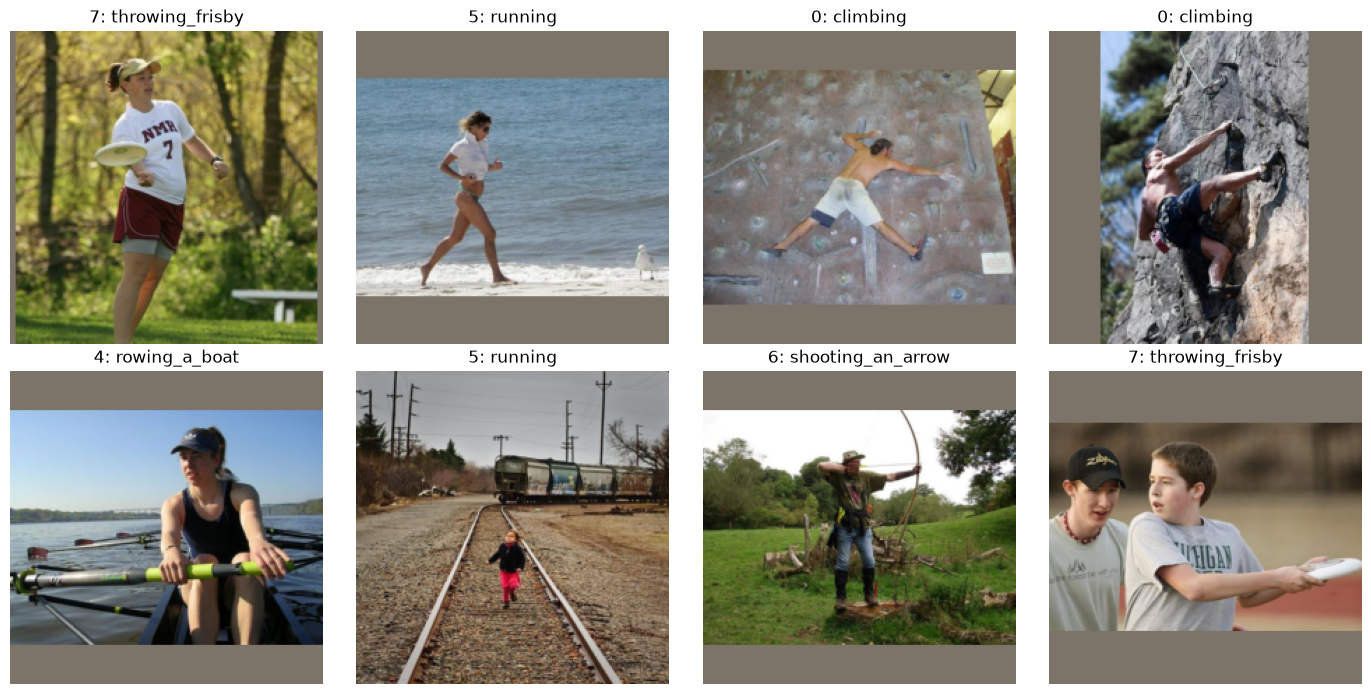

In [22]:
# 정규화된 이미지 시각화
def denormalize(image):
    mean = torch.tensor(MEAN).view(3, 1, 1)
    std = torch.tensor(STD).view(3, 1, 1)

    image = image * std + mean

    return image.clamp(0, 1)

class_names = (
    df[["target_id", "class_name"]]
    .drop_duplicates()
    .set_index("target_id")["class_name"]
    .to_dict()
)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, ax in enumerate(axes.flat):

    # 시각화를 위한 정규화 역변환
    image = denormalize(images[i])

    # CHW → HWC
    image = image.permute(1, 2, 0).numpy()

    label = labels[i].item()

    ax.imshow(image)
    ax.set_title(f"{label}: {class_names[label]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [23]:
# 전체 데이터 전처리 검증
for split_name, loader in [
    ("Train", train_loader),
    ("Validation", val_loader),
    ("Test", test_loader)
]:
    count = 0

    for batch_images, batch_labels in loader:

        assert batch_images.shape[1:] == (3, 224, 224)
        assert batch_images.dtype == torch.float32
        assert batch_labels.dtype == torch.int64

        assert torch.isfinite(batch_images).all()
        assert ((batch_labels >= 0) & 
                (batch_labels < NUM_CLASSES)).all()

        count += len(batch_labels)

    assert count == len(loader.dataset)

    print(f"{split_name}: {count} images - OK")

Train: 640 images - OK
Validation: 160 images - OK
Test: 1231 images - OK


In [25]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

In [26]:
from src.preprocessing import (
    set_seed,
    get_dataloaders
)

set_seed(42)

train_loader, val_loader, test_loader = get_dataloaders()

In [27]:
print("Train:", len(train_loader.dataset))
print("Validation:", len(val_loader.dataset))
print("Test:", len(test_loader.dataset))

images, labels = next(iter(train_loader))

print("Images Shape:", images.shape)
print("Labels Shape:", labels.shape)

Train: 640
Validation: 160
Test: 1231
Images Shape: torch.Size([32, 3, 224, 224])
Labels Shape: torch.Size([32])
